# Market excess returns — ARMA–GARCH with makystats

**Series.** Daily Fama–French **Mkt–RF** (market excess return over the risk-free rate), percent per day. Sample used below: **2005-01-03 → 2019-12-31** (fixed window for reproducibility).

**Goal.** Build a conditional mean–variance model **step by step**: start from a weak specification, read diagnostics, and only then add features that economic theory and residual tests justify.

**What makystats shows.** Joint MLE for mean and variance, GJR leverage, Student-t innovations, and theory-guided `select_order` — not ARMA then GARCH in two disconnected steps.

**Links.** [PyPI](https://pypi.org/project/makystats/) · [Docs](https://lauret-boris.github.io/makystats/) · [GitHub](https://github.com/Lauret-Boris/makystats)


## 1. Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from makystats import arma_garch, select_order
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.0)
plt.rcParams["axes.titlesize"] = 12

## 2. Data

Ken French daily factors. We model **MktRF** only (excess return). Keeping a **fixed calendar window** avoids silent changes when the CSV is updated later.


In [2]:
path = "data/ff_mkt_rf_daily.csv"
raw = pd.read_csv(path, parse_dates=True, index_col=0)
y = raw.loc["2005-01-01":"2019-12-31", "MktRF"].astype(float).dropna()
y.name = "MktRF"

print("Loaded from:", path)
print(y.index.min().date(), "→", y.index.max().date(), f"({len(y)} obs.)")
y.describe().round(3)

Loaded from: data/ff_mkt_rf_daily.csv
2005-01-03 → 2019-12-31 (3775 obs.)


count    3775.000
mean        0.037
std         1.166
min        -8.960
25%        -0.410
50%         0.070
75%         0.550
max        11.360
Name: MktRF, dtype: float64

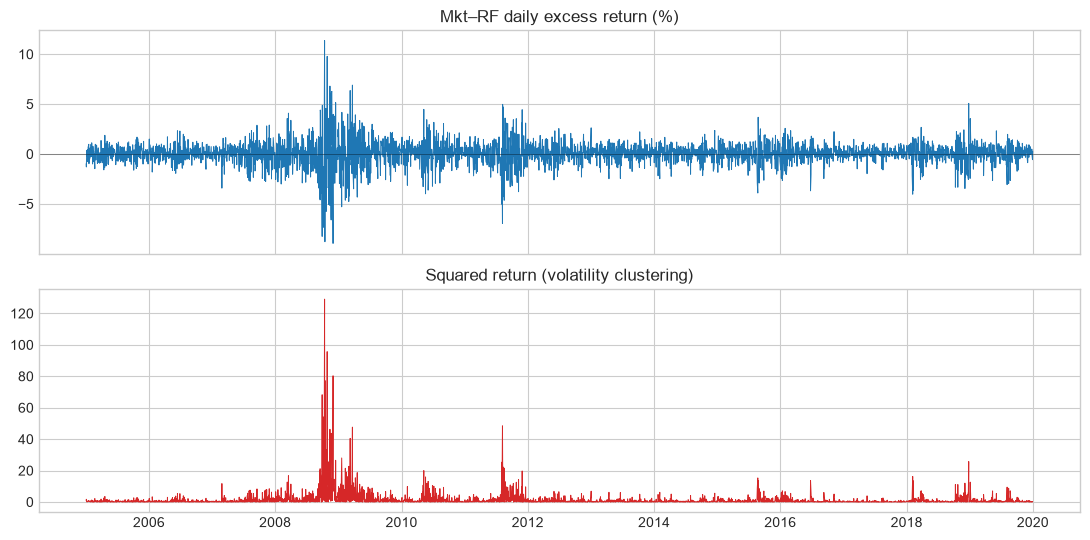

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(y, lw=0.7, color="C0")
axes[0].set_title("Mkt–RF daily excess return (%)")
axes[0].axhline(0, color="k", lw=0.5, alpha=0.5)
axes[1].plot(y**2, lw=0.7, color="C3")
axes[1].set_title("Squared return (volatility clustering)")
fig.tight_layout()
plt.show()

### Stylised facts (why GARCH enters before a rich ARMA)

| Fact | What we expect on daily equity excess returns |
|------|-----------------------------------------------|
| **Mean** | Near efficient-market behaviour: weak serial correlation (at most short AR/MA). |
| **Variance** | **Clustering**: quiet periods and stormy periods alternate (Mandelbrot; Engle). |
| **Asymmetry** | **Leverage**: bad news often raises volatility more than good news (Black; Christie). |
| **Tails** | Heavier than Gaussian (crashes, jumps). |

So the default variance workhorse is **GARCH(1,1)** (Hansen & Lunde): not a high-order ARCH grid chosen at random. Mean lags are added **only if** residual tests still require them.


In [4]:
def ljung_box_table(series, lags=(5, 10, 20), title=""):
    d = acorr_ljungbox(series, lags=list(lags), return_df=True)
    d.index.name = "lag"
    print(title)
    display(d.round(4))

ljung_box_table(y - y.mean(), title="Ljung–Box on demeaned returns")
ljung_box_table((y - y.mean()) ** 2, title="Ljung–Box on squared demeaned returns")

Ljung–Box on demeaned returns


,lb_stat,lb_pvalue
lag,,
5,50.6233,0.0
10,57.1762,0.0
20,117.4815,0.0


Ljung–Box on squared demeaned returns


,lb_stat,lb_pvalue
lag,,
5,1809.5784,0.0
10,3435.0250,0.0
20,5885.9545,0.0


**Reading.** Serial correlation in levels is present but modest relative to the **massive** dependence in squares. That orders the agenda: **variance model first**, mean refinement second.


## 3. Step A — Constant mean, constant variance (baseline)

A constant mean with i.i.d. normal errors is the weakest usable model. It is **not** a serious description of daily equity returns; it is the benchmark diagnostics will reject.


In [5]:
def report(name, res):
    print("=== %s ===" % name)
    print("LogL=%.2f  AIC=%.2f  BIC=%.2f" % (res.loglik, res.aic, res.bic))
    print(
        "Ljung–Box resid p=%.4g | resid2 p=%.4g | Jarque–Bera p=%.4g"
        % (res.ljungbox_resid_pval, res.ljungbox_resid2_pval, res.jarque_bera_pval)
    )
    display(res.coef_table.round(4))

res_A = arma_garch(
    y, mean="Constant", ar=0, ma=0, r=0, s=0, dist="normal", trend="c"
).fit(verbose=False)
res_A.summary()


   ARMA(0,0) - GARCH(0,0) — MLE (MLE)
   Mean: Constant  |  trend=c  |  Distribution: NORMAL  |  Optimiseur: BFGS non contraint (reparam.)
   Backcast exponentiel: lambda = 0.7  |  Cov: OPG
Log-Likelihood : -5935.998210
AIC            : 11875.9964
BIC            : 11888.4687
Observations   : 3775
Paramètres     : 2

--- Coefficients (IC 95% dans self.coef_table) ---
          Coeff   Std.Err      z-Stat     Prob.  CI_low_95  CI_high_95
const  0.036967  0.019003    1.945333  0.051735  -0.000278    0.074212
omega  1.359372  0.012519  108.588742  0.000000   1.334836    1.383908

--- Diagnostic ---
alpha+beta = 0.000000
Ljung-Box (10) sur résidus std : p-val = 0.0000
Ljung-Box (10) sur carrés std  : p-val = 0.0000
Jarque-Bera (normalité résidus std) : stat=17460.5654  p-val=0.0000


**Diagnosis A.** Ljung–Box on residuals and on squared residuals both reject hard; Jarque–Bera rejects normality. Information criteria will drop sharply once volatility dynamics are allowed.


## 4. Step B — Constant mean + GARCH(1,1) (Gaussian)

**Why (1,1)?** For daily equity series, **GARCH(1,1)** is the standard low-order specification: one shock term alpha and one persistence term beta. Higher (r,s) are not introduced without evidence that (1,1) leaves structured residual energy.

Joint MLE estimates the constant mean and the variance parameters **together**.


In [6]:
res_B = arma_garch(
    y,
    mean="Constant",
    ar=0,
    ma=0,
    vol="GARCH",
    r=1,
    s=1,
    dist="normal",
    trend="c",
).fit(verbose=False)
report("B — Constant + GARCH(1,1) normal", res_B)
alpha = float(res_B.coef_table.loc["alpha(1)", "Coeff"])
beta = float(res_B.coef_table.loc["beta(1)", "Coeff"])
print("Persistence alpha+beta ≈ %.4f" % (alpha + beta))

=== B — Constant + GARCH(1,1) normal ===
LogL=-4951.56  AIC=9911.13  BIC=9936.07
Ljung–Box resid p=0.02423 | resid2 p=0.03989 | Jarque–Bera p=9.341e-145


,Coeff,Std.Err,z-Stat,Prob.,CI_low_95,CI_high_95
const,0.0710,0.0127,5.6020,0.0,0.0462,0.0959
omega,0.0259,0.0026,9.7952,0.0,0.0207,0.0311
alpha(1),0.1221,0.0087,14.0754,0.0,0.1051,0.1391
beta(1),0.8538,0.0099,86.4765,0.0,0.8345,0.8732


Persistence alpha+beta ≈ 0.9760


**Diagnosis B.**
- AIC/BIC **collapse** versus constant variance → clustering was the main defect.
- Squared-residual Ljung–Box improves a lot but may remain imperfect.
- Jarque–Bera still fails → **tails** thicker than normal.
- Residual levels may still show mild serial correlation → optional short mean lag later.

Next, theory points to **asymmetric** news impact, not a random extra ARCH lag.


## 5. Step C — GJR-GARCH (leverage) + Gaussian

**Economic rationale.** Equity volatility often reacts more to negative returns than to positive ones (leverage / volatility-feedback). **GJR/TARCH** adds a threshold term gamma on negative shocks. We keep **(1,1)** dynamics: same persistence story, one asymmetry parameter.


In [7]:
res_C = arma_garch(
    y,
    mean="Constant",
    ar=0,
    ma=0,
    vol="GJR",
    r=1,
    s=1,
    o=1,
    dist="normal",
    trend="c",
).fit(verbose=False)
report("C — Constant + GJR(1,1) normal", res_C)

=== C — Constant + GJR(1,1) normal ===
LogL=-4865.05  AIC=9740.10  BIC=9771.28
Ljung–Box resid p=0.04067 | resid2 p=0.1735 | Jarque–Bera p=6.405e-145


,Coeff,Std.Err,z-Stat,Prob.,CI_low_95,CI_high_95
const,0.0299,0.0129,2.3250,0.0201,0.0047,0.0551
omega,0.0259,0.0022,11.6049,0.0000,0.0215,0.0303
alpha(1),-0.0174,0.0069,-2.5371,0.0112,-0.0308,-0.0040
gamma(1),0.2239,0.0154,14.5753,0.0000,0.1938,0.2540
beta(1),0.8775,0.0089,98.5604,0.0000,0.8601,0.8950


**Diagnosis C.** If gamma is positive and significant, asymmetry is not optional decoration: it is required by the data. AIC/BIC typically beat symmetric GARCH. Gaussian tails remain a problem → Student-t.


## 6. Step D — GJR + Student-t innovations

**Why t?** Daily excess returns have **excess kurtosis**. A Student-t innovation (degrees of freedom nu) is the usual parametric fix inside the same MLE. We do **not** jump to exotic laws before reading nu and the IC gain.


In [8]:
res_D = arma_garch(
    y,
    mean="Constant",
    ar=0,
    ma=0,
    vol="GJR",
    r=1,
    s=1,
    o=1,
    dist="t",
    trend="c",
).fit(verbose=False)
report("D — Constant + GJR(1,1) Student-t", res_D)

=== D — Constant + GJR(1,1) Student-t ===
LogL=-4784.38  AIC=9580.77  BIC=9618.19
Ljung–Box resid p=0.02266 | resid2 p=0.2105 | Jarque–Bera p=1.768e-172


,Coeff,Std.Err,z-Stat,Prob.,CI_low_95,CI_high_95
const,0.0560,0.0115,4.8697,0.0000,0.0335,0.0786
omega,0.0208,0.0029,7.1494,0.0000,0.0151,0.0265
alpha(1),-0.0211,0.0105,-2.0107,0.0444,-0.0416,-0.0005
gamma(1),0.2456,0.0231,10.6510,0.0000,0.2004,0.2908
beta(1),0.8770,0.0113,77.3390,0.0000,0.8548,0.8992
nu,6.3501,0.6695,9.4855,0.0000,5.0380,7.6622


**Diagnosis D.** Large IC gain versus Gaussian GJR is common; nu often lands in a finite range (e.g. around 6–10), i.e. heavier tails than normal but finite variance. Ljung–Box on residual **levels** can still be marginally significant → check whether a **short** mean lag is warranted.


## 7. Step E — Mean dynamics: theory first, then tests

**Theory.** At the **daily** frequency, equity excess returns are close to a martingale difference after a constant risk premium. Rich ARMA orders are easy to overfit.

**Rule used here.**
1. Prefer **constant mean** if residual Ljung–Box is acceptable after a good variance model.
2. Allow **AR(1)** or **MA(1)** only as a local correction (nonsynchronous trading / weak serial correlation).
3. Compare with **BIC** (stronger parsimony penalty than AIC on T ≈ 4000).

We estimate three candidates **sharing** GJR(1,1) + Student-t.


In [9]:
res_E0 = res_D  # constant mean
res_E1 = arma_garch(
    y, mean="AR", ar=1, ma=0, vol="GJR", r=1, s=1, o=1, dist="t", trend="c"
).fit(verbose=False)
res_E11 = arma_garch(
    y, mean="ARMA", ar=1, ma=1, vol="GJR", r=1, s=1, o=1, dist="t", trend="c"
).fit(verbose=False)

rows = []
for name, res in [
    ("Const + GJR-t", res_E0),
    ("AR(1) + GJR-t", res_E1),
    ("ARMA(1,1) + GJR-t", res_E11),
]:
    rows.append(
        {
            "model": name,
            "logL": res.loglik,
            "AIC": res.aic,
            "BIC": res.bic,
            "LB_resid_p": res.ljungbox_resid_pval,
            "LB_resid2_p": res.ljungbox_resid2_pval,
        }
    )
comp = pd.DataFrame(rows).set_index("model")
display(comp.round(4))
report("E — AR(1) + GJR-t", res_E1)

,logL,AIC,BIC,LB_resid_p,LB_resid2_p
model,,,,,
Const + GJR-t,-4784.3850,9580.7699,9618.1869,0.0227,0.2105
AR(1) + GJR-t,-4778.8800,9571.7599,9615.4112,0.1150,0.2068
"ARMA(1,1) + GJR-t",-4775.1286,9566.2572,9616.1444,0.3012,0.2074


=== E — AR(1) + GJR-t ===
LogL=-4778.88  AIC=9571.76  BIC=9615.41
Ljung–Box resid p=0.115 | resid2 p=0.2068 | Jarque–Bera p=1.051e-166


,Coeff,Std.Err,z-Stat,Prob.,CI_low_95,CI_high_95
const,0.0602,0.0110,5.4617,0.0000,0.0386,0.0818
AR(1),-0.0448,0.0169,-2.6419,0.0082,-0.0780,-0.0116
omega,0.0200,0.0028,7.0547,0.0000,0.0145,0.0256
alpha(1),-0.0194,0.0104,-1.8615,0.0627,-0.0399,0.0010
gamma(1),0.2349,0.0221,10.6280,0.0000,0.1916,0.2782
beta(1),0.8799,0.0112,78.7223,0.0000,0.8580,0.9018
nu,6.3282,0.6688,9.4627,0.0000,5.0175,7.6390


**Reading the mean comparison.**
- If BIC prefers the **constant** mean, stop there: residual correlation was not worth extra parameters.
- If **AR(1)** wins BIC and cleans Ljung–Box, keep one autoregressive lag — still a theory-compatible "weak dependence" fix.
- **ARMA(1,1)** may improve AIC but lose on BIC; treat it as optional, not automatic.


## 8. Theory-guided `select_order` (makystats)

After the diagnostic path, formalise the comparison in **one** grid. Information criteria share a common burn-in.

| Dimension | Grid | Reason |
|-----------|------|--------|
| r, s | **1 only** | GARCH(1,1) / GJR(1,1) workhorse |
| Variance | `garch`, `gjr` | Symmetry vs leverage |
| Dist | `normal`, `t` | Gaussian vs fat tails |
| Mean lags | p ∈ {0,1}, q = 0 | Constant vs AR(1); no free MA explosion |
| `mean` | **`"AR"`** | Search helper varies p (and q if requested). Avoid `mean="ARMA"` in `select_order`. |
| criterion | **BIC** | Large T |

`return_best=True` returns a fitted model ready for plots.


In [10]:
table, best = select_order(
    y,
    p_range=range(0, 2),
    q_range=[0],
    r_range=[1],
    s_range=[1],
    dist=["normal", "t"],
    variance_model=["garch", "gjr"],
    criterion="bic",
    mean="AR",
    trend="c",
    o=1,
    verbose=False,
    n_jobs=1,
    return_best=True,
)
display(table[["aic", "bic", "ok"]].sort_values("bic").head(8))
print("Best by BIC:", table.attrs.get("best"))

,aic,bic,ok
label,,,
"ARMA(0,0)-gjr(1,1)-t",9577.537341,9614.952685,True
"ARMA(1,0)-gjr(1,1)-t",9571.759931,9615.411166,True
"ARMA(1,0)-garch(1,1)-t",9710.667685,9748.083030,True
"ARMA(0,0)-garch(1,1)-t",9719.042500,9750.221954,True
"ARMA(1,0)-gjr(1,1)-normal",9730.549727,9767.965071,True
"ARMA(0,0)-gjr(1,1)-normal",9737.230656,9768.410110,True
"ARMA(1,0)-garch(1,1)-normal",9900.407786,9931.587240,True
"ARMA(0,0)-garch(1,1)-normal",9908.177590,9933.121153,True


Best by BIC: ARMA(0,0)-gjr(1,1)-t


## 9. Preferred specification — diagnostics and volatility path

Use the **`select_order` winner** when it is well identified; otherwise fall back to the diagnostic path (constant vs AR(1) GJR-t).


Using select_order best: ARMA(0,0)-gjr(1,1)-t BIC=9618.19
=== Preferred fit used for plots ===
LogL=-4784.38  AIC=9580.77  BIC=9618.19
Ljung–Box resid p=0.02266 | resid2 p=0.2105 | Jarque–Bera p=1.768e-172


,Coeff,Std.Err,z-Stat,Prob.,CI_low_95,CI_high_95
const,0.0560,0.0115,4.8697,0.0000,0.0335,0.0786
omega,0.0208,0.0029,7.1494,0.0000,0.0151,0.0265
alpha(1),-0.0211,0.0105,-2.0107,0.0444,-0.0416,-0.0005
gamma(1),0.2456,0.0231,10.6510,0.0000,0.2004,0.2908
beta(1),0.8770,0.0113,77.3390,0.0000,0.8548,0.8992
nu,6.3501,0.6695,9.4855,0.0000,5.0380,7.6622


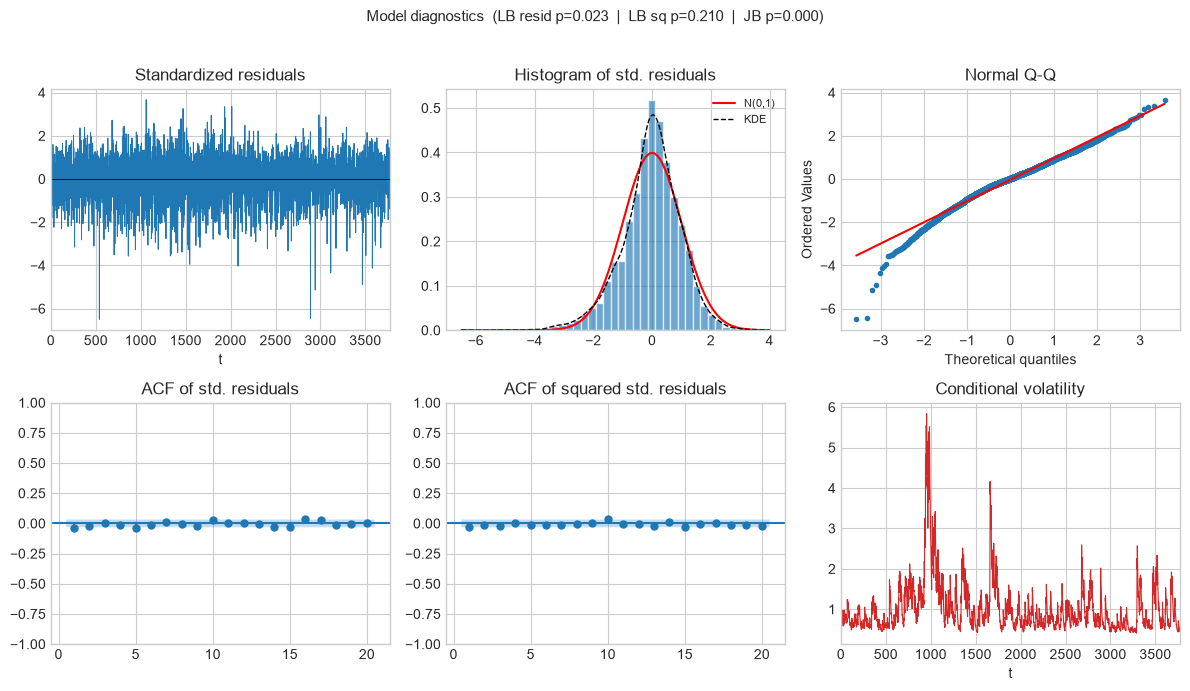

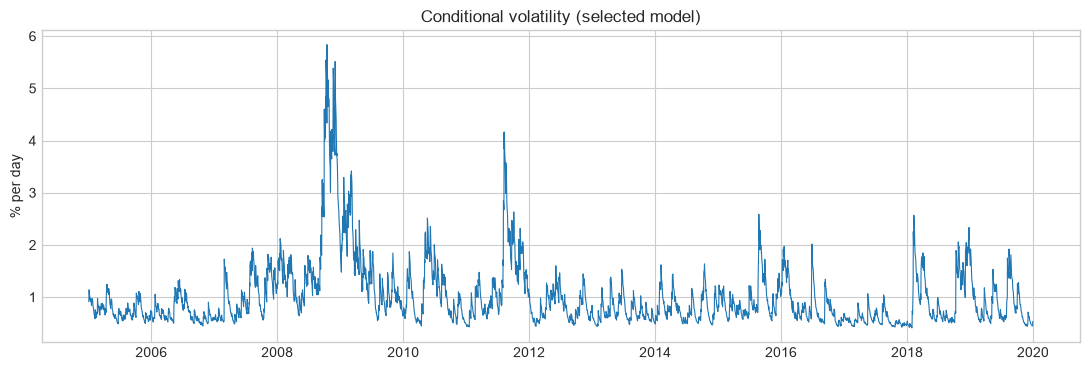

In [11]:
res = best  # BIC winner from select_order
print("Using select_order best:", table.attrs.get("best"), "BIC=%.2f" % res.bic)
report("Preferred fit used for plots", res)

fig = res.plot_diagnostics()
plt.show()

vol_arr = np.asarray(res.conditional_volatility, dtype=float)
vol = pd.Series(vol_arr, index=y.index[-len(vol_arr):])
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(vol, color="C0", lw=0.8)
ax.set_title("Conditional volatility (selected model)")
ax.set_ylabel("% per day")
fig.tight_layout()
plt.show()

## 10. Takeaways

1. **Order of attack:** squared-return dependence dominates level dependence on daily Mkt–RF → **GARCH before rich ARMA**.
2. **GARCH(1,1)** is the variance default; **GJR** is added for **leverage**, not because a larger (r,s) looked prettier.
3. **Student-t** answers Jarque–Bera / kurtosis; nu is estimated inside the same joint MLE.
4. **Mean lags** stay minimal (constant or AR(1)), justified by residual Ljung–Box and **BIC**.
5. **`select_order`** packs mean × variance × distribution into one comparable table — the practical expression of joint modelling in makystats.

Data source: Ken French data library (daily factors). Reduced-form volatility exercise, not an asset-pricing model of the equity premium.
